In [ ]:
# To download the dataset, use this link: https://www.kaggle.com/datasets/bhavikjikadara/dog-and-cat-classification-dataset
%pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import kagglehub

# Downloads the Cat/Dog dataset automatically (cached after the first run)
DATASET_DIR = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Dataset downloaded to:", DATASET_DIR)

# Folder where the cleaned CSV and the trained model checkpoint are saved
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath("working")
os.makedirs(WORK_DIR, exist_ok=True)
print("Working directory:", WORK_DIR)

file_count = sum(len(files) for _, _, files in os.walk(DATASET_DIR))
print("Files found in dataset:", file_count)

In [2]:
# CELL 1
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA Available: True
GPU: Tesla T4


In [ ]:
# cell 2
DATASET_PATH = Path(DATASET_DIR)

print("Dataset exists:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    for item in DATASET_PATH.rglob("*"):
        if item.is_dir():
            print(item)

In [4]:
# cell 3
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = []

for item in DATASET_PATH.rglob("*"):
    if item.is_file():
        file_extension = item.suffix.lower()
        if file_extension in IMAGE_EXTENSIONS:
            image_files.append(item)
print("Total images found:", len(image_files))

print("Total images:", len(image_files))

# Count images by their parent folder
folder_counts = {}

for image_path in image_files:
    folder = image_path.parent.name
    folder_counts[folder] = folder_counts.get(folder, 0) + 1

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count} images")

Total images found: 24998
Total images: 24998
Cat: 12499 images
Dog: 12499 images


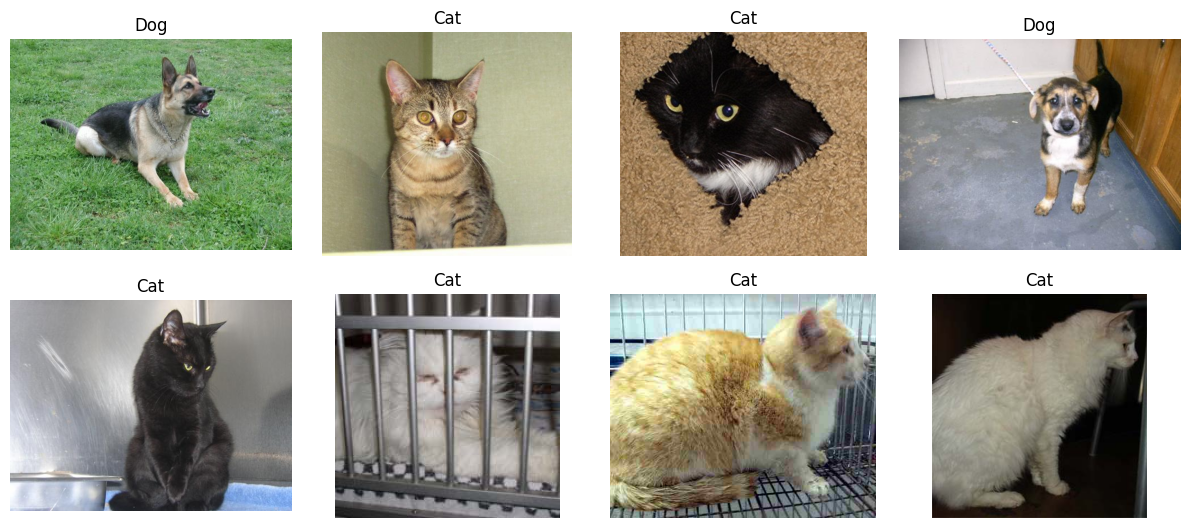

In [5]:
# cell 4 
random.seed(42)

sample_images = random.sample(
    image_files,
    min(8, len(image_files))
)

plt.figure(figsize=(12, 8))

for i, image_path in enumerate(sample_images):
    img = Image.open(image_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(image_path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# cell 5
import pandas as pd
from pathlib import Path

data = []

for img_path in image_files:
    folder_name = img_path.parent.name.lower()

    if folder_name == "cat":
        label = "cat"
    elif folder_name == "dog":
        label = "dog"
    else:
        continue

    data.append({
        "image_path": str(img_path),
        "label": label
    })

df = pd.DataFrame(data)

print("Total labeled images:", len(df))
print(df["label"].value_counts())

Total labeled images: 24998
label
cat    12499
dog    12499
Name: count, dtype: int64


In [7]:
# cell 6 
label_mapping = {
    "cat": 0,
    "dog": 1
}

df["label"] = df["label"].map(label_mapping)

print(df.head())
print(df["label"].value_counts())

                                          image_path  label
0  /kaggle/input/datasets/bhavikjikadara/dog-and-...      0
1  /kaggle/input/datasets/bhavikjikadara/dog-and-...      0
2  /kaggle/input/datasets/bhavikjikadara/dog-and-...      0
3  /kaggle/input/datasets/bhavikjikadara/dog-and-...      0
4  /kaggle/input/datasets/bhavikjikadara/dog-and-...      0
label
0    12499
1    12499
Name: count, dtype: int64


In [8]:
# # cell 6.1
# from PIL import Image
# from tqdm.auto import tqdm

# valid_indices = []
# corrupted_files = []

# for idx, path in tqdm(df["image_path"].items(), total=len(df)):
#     try:
#         with Image.open(path) as img:
#             img.verify()              # checks the file structure
#         with Image.open(path) as img:
#             img.load()                # fully decodes pixels, catches truncated files
#             if img.width < 10 or img.height < 10:
#                 raise ValueError("Image too small")
#         valid_indices.append(idx)
#     except Exception as e:
#         corrupted_files.append((path, str(e)))

# print(f"Total checked:   {len(df)}")
# print(f"Valid images:    {len(valid_indices)}")
# print(f"Corrupted found: {len(corrupted_files)}")

# for path, err in corrupted_files[:10]:
#     print(" -", path, "|", err)

# df = df.loc[valid_indices].reset_index(drop=True)
# print("\nClean dataframe size:", len(df))
# print(df["label"].value_counts())

In [9]:
#cell 6.2 Save after cleaning
df.to_csv(f"{WORK_DIR}/clean_df.csv", index=False)
print("Saved:", len(df), "rows")

Saved: 24998 rows


Cleaned dataset loaded successfully!
Total images: 24998

Dataset preview:


,image_path,label
0,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
1,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
2,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
3,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
4,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0



Class counts:
label
0    12499
1    12499
Name: count, dtype: int64


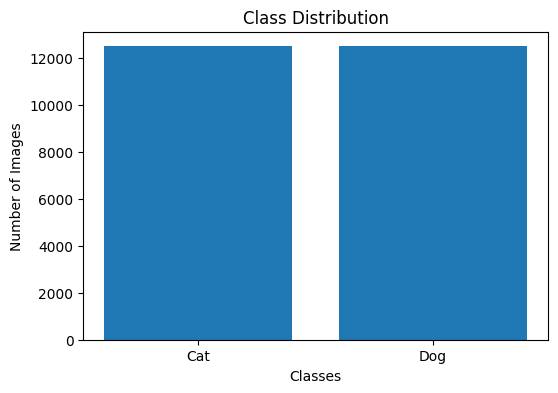

In [10]:

# CELL 7: LOAD CLEANED DATA AND CHECK CLASS DISTRIBUTION

import os
import pandas as pd
import matplotlib.pyplot as plt

CLEAN_DATA_PATH = f"{WORK_DIR}/clean_df.csv"

if not os.path.exists(CLEAN_DATA_PATH):
    raise FileNotFoundError(
        "clean_df.csv not found. The saved file may not have "
        "persisted after restarting the Kaggle session."
    )

# Load previously cleaned dataset
df = pd.read_csv(CLEAN_DATA_PATH)

print("Cleaned dataset loaded successfully!")
print("Total images:", len(df))
print("\nDataset preview:")
display(df.head())

# Class distribution
class_counts = df["label"].value_counts().sort_index()
print("\nClass counts:")
print(class_counts)

plt.figure(figsize=(6, 4))

plt.bar(
    ["Cat", "Dog"],
    class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.show()


In [11]:
# cell 8 
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:  ", len(train_df))
print("Validation:", len(val_df))
print("Testing:   ", len(test_df))

# Check 1: no image appears in more than one split
train_set = set(train_df["image_path"])
val_set   = set(val_df["image_path"])
test_set  = set(test_df["image_path"])

print("\nTrain/Val overlap: ", len(train_set & val_set))
print("Train/Test overlap:", len(train_set & test_set))
print("Val/Test overlap:  ", len(val_set & test_set))

# Check 2: class balance in each split
for name, split in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"\n{name} class distribution:")
    print(split["label"].value_counts(normalize=True).sort_index().round(4))

Training:   17498
Validation: 3750
Testing:    3750

Train/Val overlap:  0
Train/Test overlap: 0
Val/Test overlap:   0

Train class distribution:
label
0    0.5
1    0.5
Name: proportion, dtype: float64

Val class distribution:
label
0    0.5
1    0.5
Name: proportion, dtype: float64

Test class distribution:
label
0    0.5
1    0.5
Name: proportion, dtype: float64


In [12]:
# CELL 9: Preprocessing and Augmentation

IMG_SIZE = 224

# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]


# TRAINING TRANSFORM
train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.80, 1.0),
        ratio=(0.85, 1.15)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.08, 0.08),
        scale=(0.95, 1.05)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.03
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    ),

    transforms.RandomErasing(
        p=0.2,
        scale=(0.02, 0.08),
        ratio=(0.3, 3.3),
        value=0
    )
])


# VALIDATION AND TEST TRANSFORM
val_test_transform = transforms.Compose([

    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])


print("Image size:", IMG_SIZE)
print("Training transformations configured.")
print("Validation and testing transformations configured.")


Image size: 224
Training transformations configured.
Validation and testing transformations configured.


In [13]:
# cell 10 
from torch.utils.data import Dataset

class CatDogDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        dataframe = dataframe.reset_index(drop=True)
        self.image_paths = dataframe["image_path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        try:
            image = Image.open(self.image_paths[idx]).convert("RGB")
        except Exception as e:
            # Safety net: skip a bad file by using the next sample instead of crashing
            print(f"Warning: could not read {self.image_paths[idx]} ({e})")
            return self.__getitem__((idx + 1) % len(self))

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(self.labels[idx], dtype=torch.long)

In [14]:
# cell 11 
train_dataset = CatDogDataset(
    train_df,
    transform=train_transform
)

val_dataset = CatDogDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = CatDogDataset(
    test_df,
    transform=val_test_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 17498
Validation dataset: 3750
Testing dataset: 3750


In [15]:
# cell 12 
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label.item())
print("Image minimum:", image.min().item())
print("Image maximum:", image.max().item())

Image shape: torch.Size([3, 224, 224])
Label: 1
Image minimum: -2.015155553817749
Image maximum: 1.9079740047454834


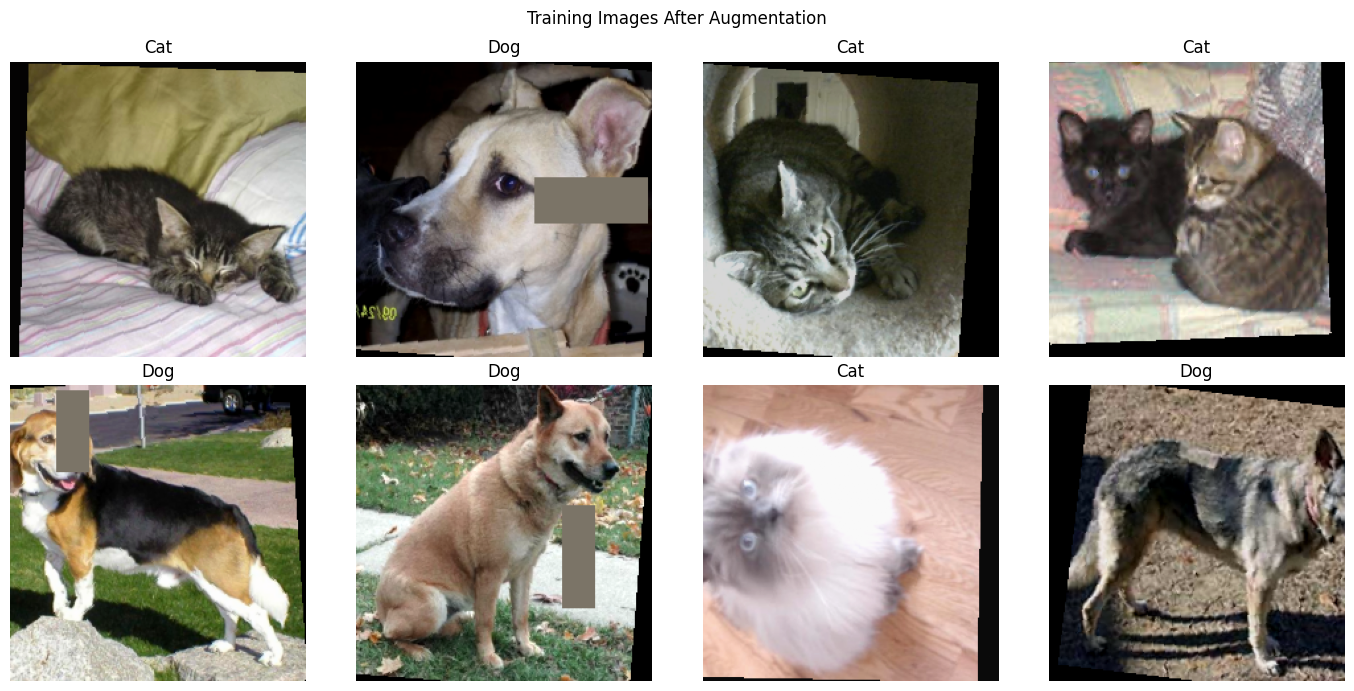

In [16]:

# cell 13

mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

def denormalize(img):
    return (
        img * std_t + mean_t
    ).clamp(0, 1).permute(1, 2, 0)

# Display 8 randomly augmented images
images, labels = next(iter(
    torch.utils.data.DataLoader(
        train_dataset,
        batch_size=8,
        shuffle=True
    )
))

plt.figure(figsize=(14, 7))

for i in range(8):

    img = denormalize(images[i])

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)

    class_name = "Cat" if labels[i].item() == 0 else "Dog"

    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Training Images After Augmentation")
plt.tight_layout()
plt.show()


In [17]:

# CELL 14: OPTIMIZED DATALOADERS 

import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 64
NUM_WORKERS = 4

loader_args = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
    "persistent_workers": True,
    "prefetch_factor": 2
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=True,
    **loader_args
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_args
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_args
)

print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("GPUs available:", torch.cuda.device_count())


Batch size: 64
Workers: 4
Training batches: 273
Validation batches: 59
Testing batches: 59
GPUs available: 2


In [18]:
# cell 15
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

Images shape: torch.Size([64, 3, 224, 224])
Labels shape: torch.Size([64])
Labels: tensor([1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1,
        0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0])
Training device: cuda


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [19]:
# cell 16 (improved)
import torch.nn as nn

def conv_block(in_channels, out_channels):
    """Two convolutions, then pooling."""
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),

        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),

        nn.MaxPool2d(kernel_size=2)
    )


class CatDogCNN(nn.Module):

    def __init__(self):
        super(CatDogCNN, self).__init__()

        self.conv_block1 = conv_block(3, 32)      # 224 -> 112
        self.conv_block2 = conv_block(32, 64)     # 112 -> 56
        self.conv_block3 = conv_block(64, 128)    # 56  -> 28
        self.conv_block4 = conv_block(128, 256)   # 28  -> 14

        # Average each feature map down to a single number
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.global_pool(x)
        x = self.classifier(x)
        return x

In [20]:
# cell 17 
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Available GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

model = CatDogCNN().to(device)

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

print("\nModel initialized successfully!")
print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"\nTrainable parameters: {total_params:,}")

Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

Model initialized successfully!
DataParallel(
  (module): CatDogCNN(
    (conv_block1): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv_block2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

In [21]:
# ============================================================
# CELL 18: ADVANCED TRAINING CONFIGURATION (IMPROVED)
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim

from torch.amp import GradScaler


# ------------------------------------------------------------
# 1. GENERAL TRAINING CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 40

best_val_loss = float("inf")

CHECKPOINT_PATH = f"{WORK_DIR}/best_cat_dog_model.pth"

# Early stopping configuration
EARLY_STOPPING_PATIENCE = 10        # was 5
early_stopping_counter = 0

# Gradient clipping
GRADIENT_CLIP_NORM = 1.0


# ------------------------------------------------------------
# 2. TRAINING HISTORY
# ------------------------------------------------------------

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}


# ------------------------------------------------------------
# 3. LOSS FUNCTION
# ------------------------------------------------------------

LABEL_SMOOTHING = 0.1               # was 0.05

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)


# ------------------------------------------------------------
# 4. OPTIMIZER: ADAMW
# ------------------------------------------------------------

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-2               # was 1e-4
)


# ------------------------------------------------------------
# 5. LEARNING RATE SCHEDULER
# ------------------------------------------------------------

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,                     # was 2
    min_lr=1e-6
)


# ------------------------------------------------------------
# 6. MIXUP / CUTMIX CONFIGURATION (not used yet)
# ------------------------------------------------------------

MIX_METHOD = "none"

MIX_ALPHA = 0.2
MIX_PROB = 0.5


# ------------------------------------------------------------
# 7. AUTOMATIC MIXED PRECISION (AMP)
# ------------------------------------------------------------

scaler = GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


# ------------------------------------------------------------
# 8. CONFIGURATION SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print("ADVANCED CAT VS DOG TRAINING CONFIGURATION")
print("=" * 55)

print("\nTRAINING")
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Device:", device)
print("Available GPUs:", torch.cuda.device_count())

print("\nOPTIMIZATION")
print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Weight Decay:", optimizer.param_groups[0]["weight_decay"])
print("Loss:", criterion)
print("Label Smoothing:", LABEL_SMOOTHING)

print("\nREGULARIZATION")
print("Gradient Clipping:", GRADIENT_CLIP_NORM)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)

print("\nLEARNING RATE SCHEDULER")
print("Scheduler:", scheduler.__class__.__name__)
print("Factor:", scheduler.factor)
print("Patience:", scheduler.patience)

print("\nMIXUP / CUTMIX")
print("Method:", MIX_METHOD)
print("Alpha:", MIX_ALPHA)
print("Probability:", MIX_PROB)

print("\nHARDWARE")
print("AMP Enabled:", scaler.is_enabled())

print("=" * 55)
print("CONFIGURATION COMPLETED SUCCESSFULLY")
print("=" * 55)

ADVANCED CAT VS DOG TRAINING CONFIGURATION

TRAINING
Epochs: 40
Batch Size: 64
Device: cuda:0
Available GPUs: 2

OPTIMIZATION
Optimizer: AdamW
Learning Rate: 0.001
Weight Decay: 0.01
Loss: CrossEntropyLoss()
Label Smoothing: 0.1

REGULARIZATION
Gradient Clipping: 1.0
Early Stopping Patience: 10

LEARNING RATE SCHEDULER
Scheduler: ReduceLROnPlateau
Factor: 0.5
Patience: 3

MIXUP / CUTMIX
Method: none
Alpha: 0.2
Probability: 0.5

HARDWARE
AMP Enabled: True
CONFIGURATION COMPLETED SUCCESSFULLY


In [22]:
# CELL 19: TRAINING FUNCTION WITH PROGRESS BAR (IMPROVED)
import random
import numpy as np
import torch
from torch.amp import autocast
from tqdm import tqdm

# Lets cuDNN pick the fastest convolution algorithm (input size is fixed)
torch.backends.cudnn.benchmark = True


def mixup_data(images, labels, alpha):
    """Blend each photo with another photo from the same batch."""
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(images.size(0), device=images.device)
    mixed = lam * images + (1 - lam) * images[index]
    return mixed, labels, labels[index], lam


def cutmix_data(images, labels, alpha):
    """Paste a patch from another photo onto each photo."""
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(images.size(0), device=images.device)

    _, _, h, w = images.shape
    cut_ratio = np.sqrt(1.0 - lam)
    cut_h, cut_w = int(h * cut_ratio), int(w * cut_ratio)

    cy, cx = np.random.randint(h), np.random.randint(w)
    y1, y2 = max(cy - cut_h // 2, 0), min(cy + cut_h // 2, h)
    x1, x2 = max(cx - cut_w // 2, 0), min(cx + cut_w // 2, w)

    mixed = images.clone()
    mixed[:, :, y1:y2, x1:x2] = images[index, :, y1:y2, x1:x2]

    # Recalculate lam from the real patch area
    lam = 1 - ((y2 - y1) * (x2 - x1)) / (h * w)
    return mixed, labels, labels[index], lam


def train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    scaler,
    gradient_clip_norm=1.0,
    mix_method="none",      # "none", "mixup", "cutmix", or "both"
    mix_alpha=0.2,
    mix_prob=0.5
):

    model.train()

    # Totals are kept on the GPU to avoid slow syncs every batch
    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        leave=False,
        dynamic_ncols=True
    )

    for step, (images, labels) in enumerate(progress_bar):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Decide whether to mix this batch
        use_mix = (mix_method != "none") and (random.random() < mix_prob)

        if use_mix:
            method = (
                random.choice(["mixup", "cutmix"])
                if mix_method == "both" else mix_method
            )
            if method == "mixup":
                images, labels_a, labels_b, lam = mixup_data(images, labels, mix_alpha)
            else:
                images, labels_a, labels_b, lam = cutmix_data(images, labels, mix_alpha)

        optimizer.zero_grad(set_to_none=True)

        with autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images)

            if use_mix:
                loss = (
                    lam * criterion(outputs, labels_a)
                    + (1 - lam) * criterion(outputs, labels_b)
                )
            else:
                loss = criterion(outputs, labels)

        if scaler.is_enabled():

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=gradient_clip_norm
            )

            scaler.step(optimizer)
            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=gradient_clip_norm
            )

            optimizer.step()

        batch_size = labels.size(0)

        running_loss += loss.detach() * batch_size

        predictions = outputs.detach().argmax(dim=1)

        if use_mix:
            correct += (
                lam * (predictions == labels_a).sum()
                + (1 - lam) * (predictions == labels_b).sum()
            )
        else:
            correct += (predictions == labels).sum()

        total += batch_size

        # Update the progress bar every 20 batches
        if step % 20 == 0:
            progress_bar.set_postfix({
                "Loss": f"{running_loss.item() / total:.4f}",
                "Accuracy": f"{100 * correct.item() / total:.2f}%"
            })

    if total == 0:
        raise RuntimeError("Training DataLoader returned no samples.")

    return running_loss.item() / total, (correct.item() / total) * 100

In [23]:
# cell 20: VALIDATION FUNCTION (IMPROVED)
import torch
from torch.amp import autocast
from tqdm import tqdm


def validate_one_epoch(model, val_loader, criterion, device):

    model.eval()

    # Totals are kept on the GPU to avoid slow syncs every batch
    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(
            val_loader,
            desc="Validation",
            leave=False,
            dynamic_ncols=True
        ):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward pass with mixed precision
            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            running_loss += loss.detach() * batch_size
            correct += (outputs.argmax(dim=1) == labels).sum()
            total += batch_size

    if total == 0:
        raise RuntimeError("Validation DataLoader returned no samples.")

    epoch_loss = running_loss.item() / total
    epoch_accuracy = (correct.item() / total) * 100

    return epoch_loss, epoch_accuracy

In [24]:
# CELL 21: MAIN TRAINING LOOP (IMPROVED)
import time
import torch
import torch.nn as nn

# An improvement must beat the best loss by at least this much
MIN_DELTA = 1e-4

# Reset training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "lr": []
}

best_val_loss = float("inf")
best_val_acc = 0.0
best_epoch = 0
early_stopping_counter = 0

start_time = time.time()

print("=" * 70)
print("STARTING MODEL TRAINING")
print("=" * 70)

for epoch in range(EPOCHS):

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_start = time.time()

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 70)

    # --------------------------------
    # 1. Training
    # --------------------------------

    train_loss, train_acc = train_one_epoch(
        model=model,
        train_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        scaler=scaler,
        gradient_clip_norm=GRADIENT_CLIP_NORM,
        mix_method=MIX_METHOD,
        mix_alpha=MIX_ALPHA,
        mix_prob=MIX_PROB
    )

    # --------------------------------
    # 2. Validation
    # --------------------------------

    val_loss, val_acc = validate_one_epoch(
        model=model,
        val_loader=val_loader,
        criterion=criterion,
        device=device
    )

    # --------------------------------
    # 3. Learning Rate Scheduler
    # --------------------------------

    current_lr = optimizer.param_groups[0]["lr"]   # LR used in this epoch

    scheduler.step(val_loss)

    # --------------------------------
    # 4. Store Training History
    # --------------------------------

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)
    history["lr"].append(current_lr)

    # --------------------------------
    # 5. Save Best Model
    # --------------------------------

    status = "No improvement"

    if val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch + 1
        early_stopping_counter = 0

        model_state = (
            model.module.state_dict()
            if isinstance(model, nn.DataParallel)
            else model.state_dict()
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "history": history
        }, CHECKPOINT_PATH)

        status = "Best model saved!"

    else:
        early_stopping_counter += 1

    # --------------------------------
    # 6. Epoch Timing
    # --------------------------------

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.time() - epoch_start

    # --------------------------------
    # 7. Epoch Summary
    # --------------------------------

    print(f"Train Loss       : {train_loss:.4f}")
    print(f"Train Accuracy   : {train_acc:.2f}%")

    print(f"Validation Loss  : {val_loss:.4f}")
    print(f"Validation Acc   : {val_acc:.2f}%")

    print(f"Learning Rate    : {current_lr:.7f}")
    print(
        f"Best So Far      : epoch {best_epoch} "
        f"(loss {best_val_loss:.4f}, acc {best_val_acc:.2f}%)"
    )

    print(f"Checkpoint       : {status}")
    print(f"Epoch Time       : {epoch_time:.2f} seconds")

    print(
        f"Early Stopping   : "
        f"{early_stopping_counter}/{EARLY_STOPPING_PATIENCE}"
    )

    print("-" * 70)

    # --------------------------------
    # 8. Early Stopping
    # --------------------------------

    if early_stopping_counter >= EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered!")
        print("Validation loss did not improve.")

        break


# --------------------------------
# 9. Final Training Summary
# --------------------------------

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.time() - start_time

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print(f"Epochs Completed : {len(history['train_loss'])}")
print(f"Best Epoch       : {best_epoch}")
print(f"Best Val Loss    : {best_val_loss:.4f}")
print(f"Best Val Acc     : {best_val_acc:.2f}%")
print(f"Total Time       : {total_time / 60:.2f} minutes")
print(f"Checkpoint       : {CHECKPOINT_PATH}")

print("=" * 70)

STARTING MODEL TRAINING

Epoch [1/40]
----------------------------------------------------------------------


Train Loss       : 0.6539
Train Accuracy   : 62.36%
Validation Loss  : 0.6031
Validation Acc   : 69.76%
Learning Rate    : 0.0010000
Best So Far      : epoch 1 (loss 0.6031, acc 69.76%)
Checkpoint       : Best model saved!
Epoch Time       : 428.40 seconds
Early Stopping   : 0/10
----------------------------------------------------------------------

Epoch [2/40]
----------------------------------------------------------------------


Train Loss       : 0.5904
Train Accuracy   : 71.53%
Validation Loss  : 0.5955
Validation Acc   : 72.27%
Learning Rate    : 0.0010000
Best So Far      : epoch 2 (loss 0.5955, acc 72.27%)
Checkpoint       : Best model saved!
Epoch Time       : 187.72 seconds
Early Stopping   : 0/10
----------------------------------------------------------------------

Epoch [3/40]
----------------------------------------------------------------------


Train Loss       : 0.5539
Train Accuracy   : 75.18%
Validation Loss  : 0.7470
Validation Acc   : 62.16%
Learning Rate    : 0.0010000
Best So Far      : epoch 2 (loss 0.5955, acc 72.27%)
Checkpoint       : No improvement
Epoch Time       : 187.26 seconds
Early Stopping   : 1/10
----------------------------------------------------------------------

Epoch [4/40]
----------------------------------------------------------------------


Train Loss       : 0.5287
Train Accuracy   : 77.72%
Validation Loss  : 0.5080
Validation Acc   : 80.59%
Learning Rate    : 0.0010000
Best So Far      : epoch 4 (loss 0.5080, acc 80.59%)
Checkpoint       : Best model saved!
Epoch Time       : 187.72 seconds
Early Stopping   : 0/10
----------------------------------------------------------------------

Epoch [5/40]
----------------------------------------------------------------------


Train Loss       : 0.4962
Train Accuracy   : 80.31%
Validation Loss  : 0.6859
Validation Acc   : 68.99%
Learning Rate    : 0.0010000
Best So Far      : epoch 4 (loss 0.5080, acc 80.59%)
Checkpoint       : No improvement
Epoch Time       : 187.78 seconds
Early Stopping   : 1/10
----------------------------------------------------------------------

Epoch [6/40]
----------------------------------------------------------------------


... (31 outputs left out)

Train Loss       : 0.2633
Train Accuracy   : 97.88%
Validation Loss  : 0.2928
Validation Acc   : 95.39%
Learning Rate    : 0.0002500
Best So Far      : epoch 30 (loss 0.2849, acc 96.05%)
Checkpoint       : No improvement
Epoch Time       : 189.96 seconds
Early Stopping   : 7/10
----------------------------------------------------------------------

Epoch [38/40]
----------------------------------------------------------------------


Train Loss       : 0.2609
Train Accuracy   : 98.02%
Validation Loss  : 0.2790
Validation Acc   : 96.67%
Learning Rate    : 0.0002500
Best So Far      : epoch 38 (loss 0.2790, acc 96.67%)
Checkpoint       : Best model saved!
Epoch Time       : 189.34 seconds
Early Stopping   : 0/10
----------------------------------------------------------------------

Epoch [39/40]
----------------------------------------------------------------------


Train Loss       : 0.2596
Train Accuracy   : 98.08%
Validation Loss  : 0.2817
Validation Acc   : 96.53%
Learning Rate    : 0.0002500
Best So Far      : epoch 38 (loss 0.2790, acc 96.67%)
Checkpoint       : No improvement
Epoch Time       : 188.72 seconds
Early Stopping   : 1/10
----------------------------------------------------------------------

Epoch [40/40]
----------------------------------------------------------------------


Train Loss       : 0.2605
Train Accuracy   : 98.06%
Validation Loss  : 0.2765
Validation Acc   : 97.01%
Learning Rate    : 0.0002500
Best So Far      : epoch 40 (loss 0.2765, acc 97.01%)
Checkpoint       : Best model saved!
Epoch Time       : 188.62 seconds
Early Stopping   : 0/10
----------------------------------------------------------------------

TRAINING COMPLETED
Epochs Completed : 40
Best Epoch       : 40
Best Val Loss    : 0.2765
Best Val Acc     : 97.01%
Total Time       : 129.73 minutes
Checkpoint       : /kaggle/working/best_cat_dog_model.pth


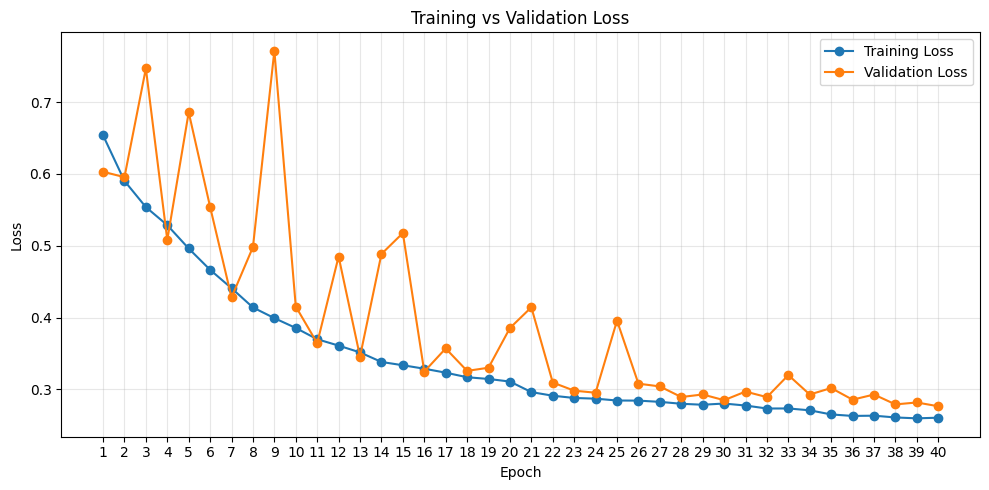

In [25]:
# cell 22
plt.figure(figsize=(10, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.plot(
    epochs_range,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.xticks(epochs_range)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# cell 23
import torch
import torch.nn as nn

# Load checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

# Handle DataParallel
if isinstance(model, nn.DataParallel):
    model.module.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

# Set model to evaluation mode
model.eval()

print("Best model loaded successfully!")

print("-" * 45)
print("Best Epoch:", checkpoint["epoch"])
print("Validation Loss:", f'{checkpoint["val_loss"]:.4f}')
print("Validation Accuracy:", f'{checkpoint["val_accuracy"]:.2f}%')
print("-" * 45)

Best model loaded successfully!
---------------------------------------------
Best Epoch: 40
Validation Loss: 0.2765
Validation Accuracy: 97.01%
---------------------------------------------


Checkpoints found: ['/kaggle/working/best_cat_dog_model.pth', '/kaggle/input/datasets/kartiksingh1305/best-model-cat-dog/best_cat_dog_model.pth', '/kaggle/input/models/kartiksingh1305/cat-dog-best-model/other/default/1/best_cat_dog_model.pth']
Using: /kaggle/working/best_cat_dog_model.pth
Loaded model from epoch 40 (val loss 0.2765, val acc 97.01%)

TEST SET EVALUATION
Samples:    3750
Loss:       0.1308
Accuracy:   96.91%
ROC-AUC:    0.9953

Classification Report:

              precision    recall  f1-score   support

         Cat     0.9646    0.9739    0.9692      1875
         Dog     0.9736    0.9643    0.9689      1875

    accuracy                         0.9691      3750
   macro avg     0.9691    0.9691    0.9691      3750
weighted avg     0.9691    0.9691    0.9691      3750



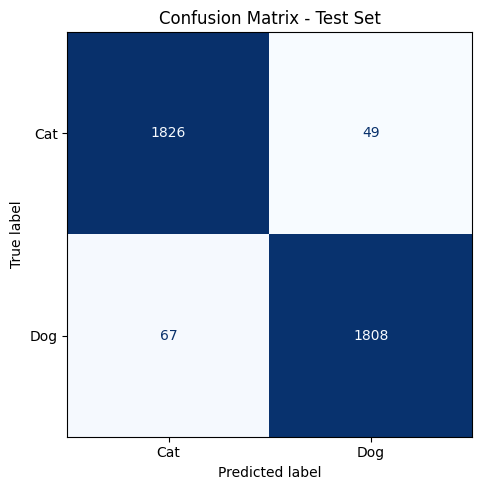


Misclassified: 116 of 3750


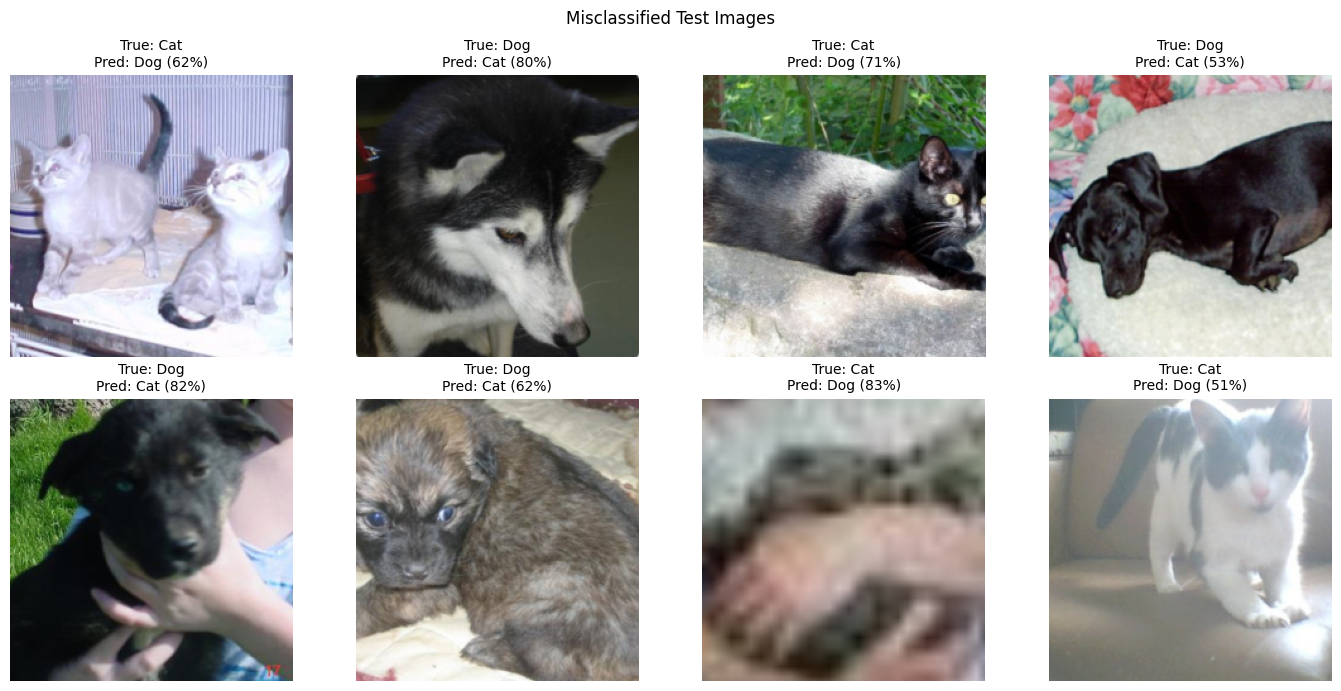

In [27]:
# cell 23 
import glob
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

# 1. Find and load the saved model
ckpt_files = glob.glob(f"{WORK_DIR}/**/*.pth", recursive=True)
print("Checkpoints found:", ckpt_files)

CHECKPOINT_PATH = ckpt_files[0]          # change the index if more than one is listed
print("Using:", CHECKPOINT_PATH)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

model = CatDogCNN().to(device)           # fresh single-GPU model, no DataParallel needed
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded model from epoch {checkpoint['epoch']} "
      f"(val loss {checkpoint['val_loss']:.4f}, val acc {checkpoint['val_accuracy']:.2f}%)")

# 2. Run the model over the test set
test_loss_sum = 0.0
all_labels, all_preds, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        probs = torch.softmax(outputs.float(), dim=1)[:, 1]   # P(dog)
        preds = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

test_loss = test_loss_sum / len(all_labels)
test_acc = (all_preds == all_labels).mean() * 100
auc = roc_auc_score(all_labels, all_probs)

# 3. Summary metrics
print("\n" + "=" * 50)
print("TEST SET EVALUATION")
print("=" * 50)
print(f"Samples:    {len(all_labels)}")
print(f"Loss:       {test_loss:.4f}")
print(f"Accuracy:   {test_acc:.2f}%")
print(f"ROC-AUC:    {auc:.4f}")
print("=" * 50)

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=["Cat", "Dog"], digits=4))

# 4. Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["Cat", "Dog"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

# 5. Misclassified images
wrong_idx = np.where(all_preds != all_labels)[0]
print(f"\nMisclassified: {len(wrong_idx)} of {len(all_labels)}")

class_names = {0: "Cat", 1: "Dog"}
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

n_show = min(8, len(wrong_idx))
if n_show > 0:
    plt.figure(figsize=(14, 7))
    for i, idx in enumerate(wrong_idx[:n_show]):
        img, _ = test_dataset[idx]
        img = (img * std + mean).permute(1, 2, 0).clamp(0, 1)
        conf = all_probs[idx] if all_preds[idx] == 1 else 1 - all_probs[idx]

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(
            f"True: {class_names[all_labels[idx]]}\n"
            f"Pred: {class_names[all_preds[idx]]} ({conf:.0%})",
            fontsize=10,
        )
        plt.axis("off")
    plt.suptitle("Misclassified Test Images")
    plt.tight_layout()
    plt.show()

MISCLASSIFICATION ANALYSIS
Dogs predicted as Cats: 67
Cats predicted as Dogs: 49
Total mistakes: 116


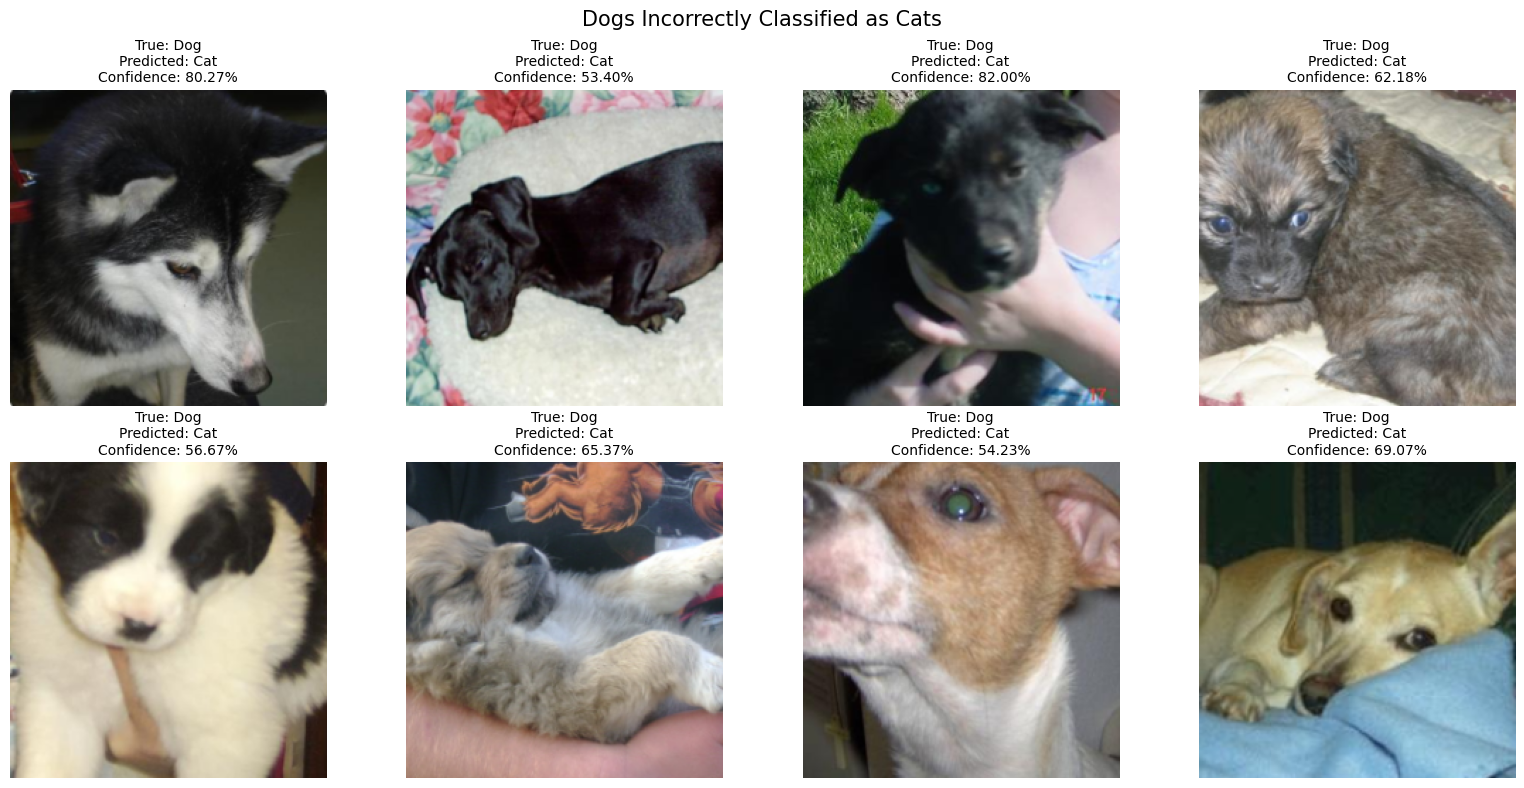

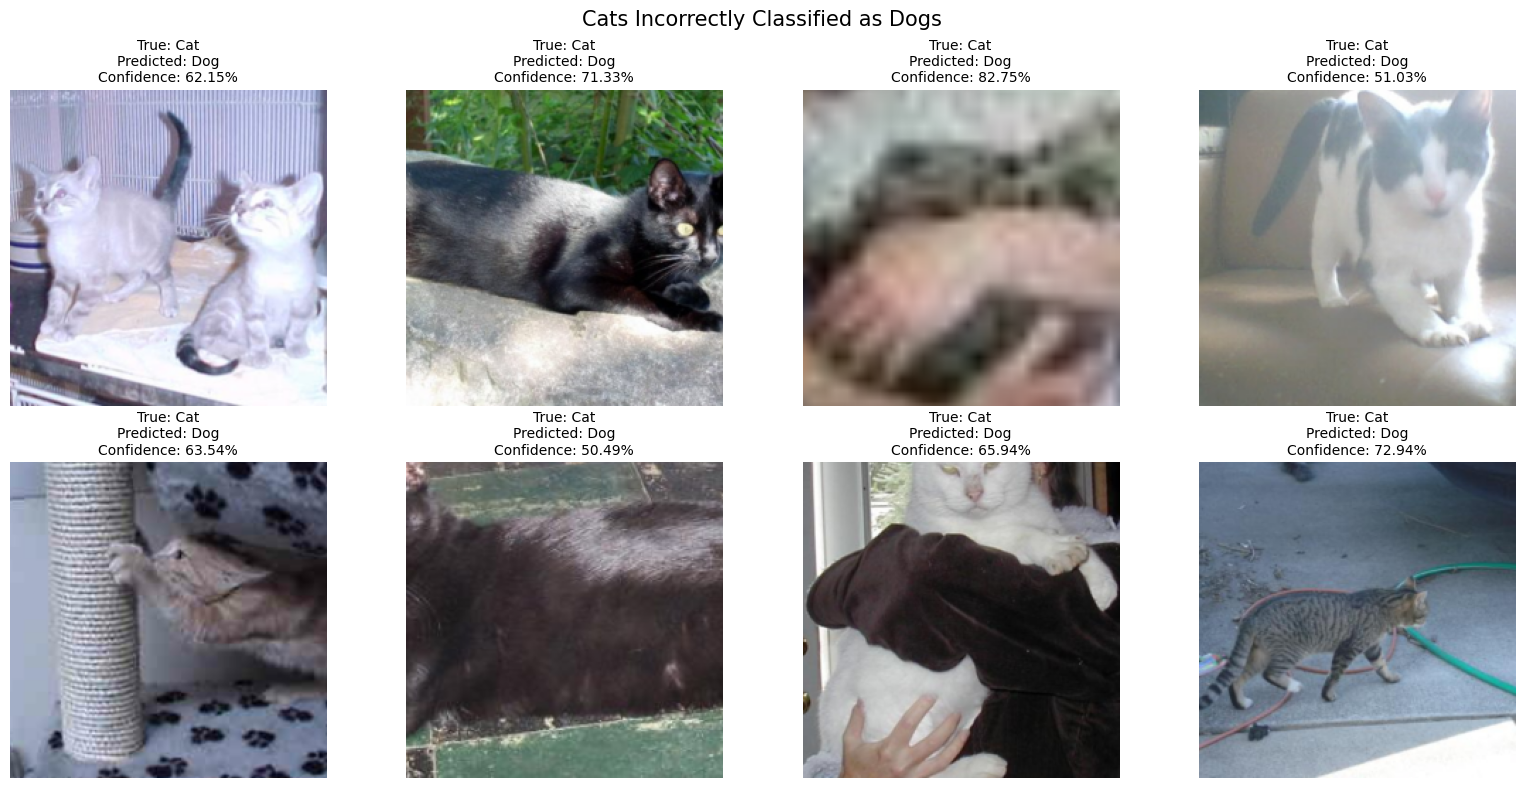

In [28]:

# 5. Separate and visualize misclassified images

# Cat = 0, Dog = 1

# Dogs incorrectly predicted as Cats
dog_as_cat_idx = np.where(
    (all_labels == 1) & (all_preds == 0)
)[0]

# Cats incorrectly predicted as Dogs
cat_as_dog_idx = np.where(
    (all_labels == 0) & (all_preds == 1)
)[0]

print("=" * 50)
print("MISCLASSIFICATION ANALYSIS")
print("=" * 50)

print(f"Dogs predicted as Cats: {len(dog_as_cat_idx)}")
print(f"Cats predicted as Dogs: {len(cat_as_dog_idx)}")
print(f"Total mistakes: {len(dog_as_cat_idx) + len(cat_as_dog_idx)}")


# Normalization values used during preprocessing
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class_names = {0: "Cat", 1: "Dog"}


def show_misclassified_images(indices, title):

    n_show = min(8, len(indices))

    if n_show == 0:
        print(f"No images found: {title}")
        return

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, idx in enumerate(indices[:n_show]):

        # Retrieve image from test dataset
        img, _ = test_dataset[int(idx)]

        # Denormalize image
        img = (img.cpu() * std + mean).permute(1, 2, 0)
        img = img.clamp(0, 1)

        true_label = int(all_labels[idx])
        predicted_label = int(all_preds[idx])

        # all_probs contains P(Dog)
        confidence = (
            all_probs[idx]
            if predicted_label == 1
            else 1 - all_probs[idx]
        )

        axes[i].imshow(img)

        axes[i].set_title(
            f"True: {class_names[true_label]}\n"
            f"Predicted: {class_names[predicted_label]}\n"
            f"Confidence: {confidence:.2%}",
            fontsize=10
        )

        axes[i].axis("off")

    # Hide unused subplot positions
    for j in range(n_show, 8):
        axes[j].axis("off")

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


# Group 1: Actual Dogs predicted as Cats
show_misclassified_images(
    dog_as_cat_idx,
    "Dogs Incorrectly Classified as Cats"
)

# Group 2: Actual Cats predicted as Dogs
show_misclassified_images(
    cat_as_dog_idx,
    "Cats Incorrectly Classified as Dogs"
)


TRAINING HISTORY SUMMARY
Epochs completed: 40
train_loss: 40 recorded values
train_accuracy: 40 recorded values
val_loss: 40 recorded values
val_accuracy: 40 recorded values
lr: 40 recorded values


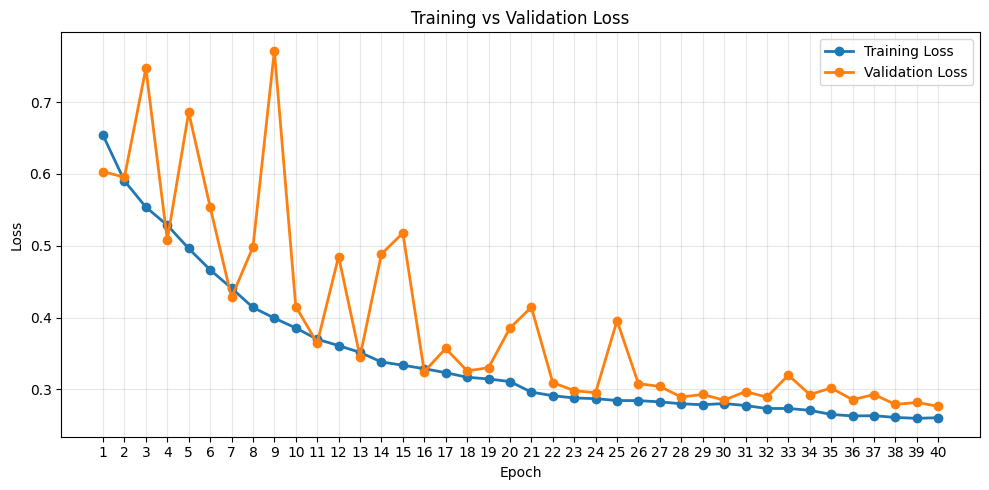

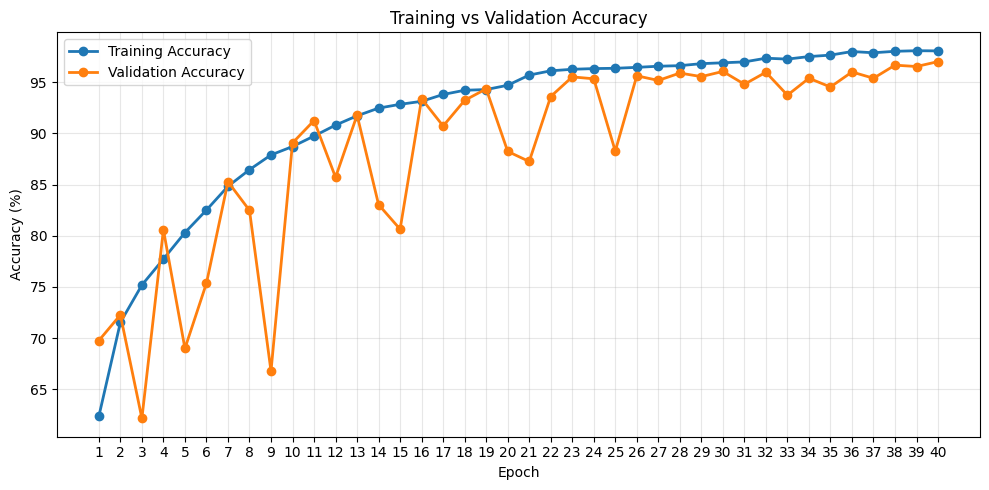


BEST MODEL PERFORMANCE
Best Epoch: 40
Training Loss: 0.2605
Validation Loss: 0.2765
Training Accuracy: 98.06%
Validation Accuracy: 97.01%

FINAL EPOCH ANALYSIS
Training Accuracy: 98.06%
Validation Accuracy: 97.01%
Accuracy Gap: 1.05 percentage points
Observation: Training and validation accuracy are relatively close.
No large accuracy gap detected.


In [29]:

# ============================================================
# TRAINING vs VALIDATION PERFORMANCE ANALYSIS
# ============================================================

import torch
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. RECOVER TRAINING HISTORY
# ------------------------------------------------------------

# If history is unavailable in memory, load it from checkpoint
if "history" not in globals() or not history.get("train_loss"):

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )

    history = checkpoint["history"]

print("=" * 60)
print("TRAINING HISTORY SUMMARY")
print("=" * 60)

epochs = len(history["train_loss"])

print("Epochs completed:", epochs)

for key, values in history.items():
    print(f"{key}: {len(values)} recorded values")

# Verify history consistency
assert all(
    len(history[key]) == epochs
    for key in [
        "train_loss",
        "val_loss",
        "train_accuracy",
        "val_accuracy"
    ]
), "Training history lengths do not match!"

epoch_range = range(1, epochs + 1)


# ------------------------------------------------------------
# 2. PLOT TRAINING vs VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epoch_range,
    history["train_loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epoch_range,
    history["val_loss"],
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.xticks(list(epoch_range))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. PLOT TRAINING vs VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epoch_range,
    history["train_accuracy"],
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epoch_range,
    history["val_accuracy"],
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

plt.xticks(list(epoch_range))
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. BEST EPOCH ANALYSIS
# ------------------------------------------------------------

best_epoch = np.argmin(history["val_loss"])

print("\n" + "=" * 60)
print("BEST MODEL PERFORMANCE")
print("=" * 60)

print("Best Epoch:", best_epoch + 1)

print(
    "Training Loss:",
    f"{history['train_loss'][best_epoch]:.4f}"
)

print(
    "Validation Loss:",
    f"{history['val_loss'][best_epoch]:.4f}"
)

print(
    "Training Accuracy:",
    f"{history['train_accuracy'][best_epoch]:.2f}%"
)

print(
    "Validation Accuracy:",
    f"{history['val_accuracy'][best_epoch]:.2f}%"
)

print("=" * 60)


# ------------------------------------------------------------
# 5. FINAL EPOCH GENERALIZATION GAP
# ------------------------------------------------------------

train_acc = history["train_accuracy"][-1]
val_acc = history["val_accuracy"][-1]

accuracy_gap = train_acc - val_acc

print("\nFINAL EPOCH ANALYSIS")

print(f"Training Accuracy: {train_acc:.2f}%")
print(f"Validation Accuracy: {val_acc:.2f}%")
print(f"Accuracy Gap: {accuracy_gap:.2f} percentage points")

if accuracy_gap > 10:
    print("Observation: Large train-validation accuracy gap.")
    print("Possible overfitting.")

elif accuracy_gap > 5:
    print("Observation: Moderate train-validation gap.")
    print("Investigate possible overfitting.")

elif accuracy_gap < -5:
    print("Observation: Validation accuracy exceeds training accuracy.")
    print("Check augmentation and regularization effects.")

else:
    print("Observation: Training and validation accuracy are relatively close.")
    print("No large accuracy gap detected.")
